# Lab workbook 5 - Growth and Accessibility

In [3]:
# Setting up:
#%pip install osmnx mapclassify folium overturemaps

import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

print("Ready! OSMnx version", ox.__version__)
print("Files in data/:", sorted(os.listdir("data"))) #reproducability point: os.listdir("data") requires 'data' folder beside notebook

Ready! OSMnx version 1.5.0
Files in data/: ['.ipynb_checkpoints', 'EDI_DataZones', 'EconomicEDI.csv', 'SG_SIMD_2020.zip', 'city_buildings.gpkg', 'city_parks.gpkg', 'city_walk.graphml', 'dundee_overture_places.gpkg', 'dundee_services.gpkg', 'dundee_walk.graphml', 'edinburgh_growth.csv', 'edinburgh_north_services.gpkg', 'ohsome_edinburgh_north_count_timeline_2026-01-01.json', 'ohsome_edinburgh_north_length_timeline_2026-01-01.json', 'ohsome_edinburgh_north_streets_by_datazone_2012-01-01_2026-01-01.json', 'ohsome_metadata.json', 'perth_bike.graphml', 'perth_residential.gpkg', 'perth_services.gpkg', 'perth_walk.graphml']


## Challenge 1: Urban Growth Using the ohsome API (St Andrews)
Change BBOX to another place (find coordinates at https://bboxfinder.com, choose the format west, south, east, north). Does the pattern repeat?.

Task is to change the Edinburgh example to another location and to then see whether the mapped building + street growth occurs. I am going to choose to do the area around the Irvine Building, St Andrews using [bbox finder](https://bboxfinder.com/#0.000000,0.000000,0.000000,0.000000) as instructed. The data source is OpenStreetMap history which is being accessed through the ohsome API website [HeiGIT](https://account.heigit.org/signup)- using the method in lab 5 part 2.

In [4]:
#Entering my API key using the lab 5 method to ensure that i am not displaying my key in this notebook
# reproducability note: will need to gain access to your own key using the website https://account.heigit.org/signup
API_KEY = getpass.getpass("Paste your ohsome API key: ")

Paste your ohsome API key:  ········


In [6]:
#Using the ohsome API example from lab 5 part 2 and changed the bbox to a samll area around Irvine
#Making sure that the bbox coords are ordered west,south,east,north

OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
BBOX = [-2.796680,56.340728,-2.789894,56.342468]          # Irvine building coords

#using the lab ohsome function to get the historical data:
def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               # stops here if API request fails
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

#this part should be counting mapped buildings and calculating residential street lengths then dividing it by 1000 to go from m -> km
buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

#next is combining results to compare the features over time:
growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

,Buildings (count),Residential streets (km)
2008,0,1.012
2009,0,0.767
2010,2,0.811
2011,8,0.785
2012,10,0.793
2013,13,0.792
2014,32,0.792
2015,34,0.792
2016,34,0.792
2017,96,0.809


In [ ]:
#next is plotting both measures to see if mapped buildings and streets show similar trends of growth or not
#code from lab 5 again

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

#next is calculating the % changes from 2012-2026 then comparing the values
#code from lab 5
change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

Figure 1: The changes seen in mapped buildings (left) and residential street lengths (right) within St Andrews, with a focus around the Irvine Building between 2008 and Januaru 2026 - data from historical OpenStreetMap data collected via ohsome API.
![st_andrews_change](screenshots/st_andrews_buildings_street_change.png)

### Description
For challenge 1, i followed the ohsome API example from lab workbook 5 and changing the bbox as required and I chose the coordinates for the Irvine BUilding, St Andrews. I kept the time period and rest of API queries the same to compare the difference in number of mapped buildings and length of residential streets as requested.

Results interpretation:
The graph shows that the number of recorded buildings increased from 10 in 2012 to 107 in January 2026 and according to the map, there was a significant jump between 2016-2017.To compare, the length of the mapped residential buildings has slightly decreased from 0.793km to 0.735km - this, alongside the recorded buildings data, could suggest that the increase in building counts may be more related to improvements in OSM mapping coverage rather than such a sudden amount of urban development. However, it is good to note that this cannot be confirmed without further evidence as the small study area also makes the percentage changes much more sensitive to individual features.

## Challenge 2: Measuring Accessibility in Dundee
1) Measure access to something else. In 2.1, change "Food shop" to "Pharmacy", "GP" or "School" and run Part 2 again.
2) Try BETA = 0.14 (half weight at 5 minutes). Who might this steeper decay represent?

In [8]:
#challenge 2.1: I am choosing to investigate schools instead of food shops using the code from the lab
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

#changed 'food shop' to 'schools' for the challenge:
shops = dundee_services[dundee_services["service"] == "School"].copy()
print(len(nodes), "street junctions and", len(shops), "school")

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 28 school


In [9]:
#Next is assigning each school to its closest network junction to let you be able to calulcate walking distance:
shops["node"] = ox.distance.nearest_nodes(G, shops.geometry.x, shops.geometry.y)
shops[["name", "node"]].head()

,name,node
134,Rosebank Primary School,12695445693
135,Our Lady's RC Primary School,12695445691
136,Longhaugh Primary School,12309812010
137,St Francis RC Primary School,12309812041
138,Glebelands Primary School,12875979421


In [ ]:
#Calulating the walking time to closest school:
#using lab coding method again
nearest = nx.multi_source_dijkstra_path_length(G, set(shops["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

#next is mapping the walking times and also school locations:
ax = nodes.plot(column="nearest_min", cmap="Oranges", vmax=20, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Minutes to nearest school"})
shops.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest school (black dots = schools)")
ax.set_axis_off()
plt.show()

Figure 2: Map showing the nearest school across Dundee's street network - calculated using network shortest path distances and also with an assumed walking speed of 80m/min. 
The black points represent the 28 school locations mapped, with the darker the orange representing the longer the walking times.

![nearest_school_map](screenshots/nearest_school_measure.png)

In [13]:
#next measures to calulate is the cumulative and gravity accessibility to shcools:
BETA = 0.069 
#beta parameter for gravity model, based on 10-minute half-life (ln(2)/10)
#starting off with keeping the initial value of BETA=0.069

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for shop_node in shops["node"]:
    distances = nx.single_source_dijkstra_path_length(G, shop_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

,nearest_min,cumulative,gravity
count,12777.00,12777.00,12777.00
mean,8.49,1.29,3.00
std,4.47,1.33,1.42
min,0.00,0.00,0.00
25%,5.17,0.00,1.91
50%,8.05,1.00,2.79
75%,11.15,2.00,4.01
max,33.44,7.00,6.73


In [ ]:
# here we plot the two measures side by side, using different colour maps and legends
#usoing the plotting example from the labs
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: schools within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: school gravity score (BETA=0.069)")
for ax in axes:
    ax.set_axis_off()
plt.show()

Figure 3: A map to show the comparison of cumalitative accessibility (left) - showing the number of schools which as reachable within a 10-minute walk, and then gravity weighted accessibility (right), using BETA=0.069 across Dundee's walking network with the darker colours indicating a greater access to schools.

![school_measure_comparison](screenshots/schools_measure_comparison.png)

In [15]:
#Challenge 2.2 - changing the distance-decay param
#I have decided to keep the Dundee walking network and school locations but changed BETA to 0.14 as requested, to see how a stronger distance-decay effect changes the gravity accessibility scores
#reusing the lab code again here:
BETA = 0.14 
#beta parameter for gravity model, based on 10-minute half-life (ln(2)/10)
#starting off with keeping the initial value of BETA=0.069

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for shop_node in shops["node"]:
    distances = nx.single_source_dijkstra_path_length(G, shop_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

,nearest_min,cumulative,gravity
count,12777.00,12777.00,12777.00
mean,8.49,1.29,1.14
std,4.47,1.33,0.71
min,0.00,0.00,0.00
25%,5.17,0.00,0.64
50%,8.05,1.00,0.99
75%,11.15,2.00,1.49
max,33.44,7.00,4.18


In [ ]:
#then mapping the school accessibility with the stronger distance-decay param
#code based off of the same geopandas plotting method in lab 5
ax = nodes.plot(column="gravity",cmap="Purples", markersize=2,legend=True, figsize=(8, 8))
ax.set_title("School gravity accessibility (BETA = 0.14)")
ax.set_axis_off()
plt.show()

Figure 4: A gravity weighted accessibility map to show the schools across Dundee using the (increased) distance-decay param Beta = 0.14. The higher scores are meant to showbetter accessibility, with more distant schools contributing less the the overall scores?

![school_accessibility_beta](screenshots/school_beta_014.png)

### Description
**Challenge 2.1 description + insights:**
I adapted the 3 accessibility measures from lab workbook5 part 3, and changed the service type from food shops to schools as requested. Then i used the given Dundee walking network and the service data, from the lab code,projected to BNG and then assigned the 28 schools to their given nearest network junctions. The outcome shows the calculated walking time to the nearest school, number of schools within a 10 minute walk and then also the gravity weighted accessibility through using the original BETA score of 0.069.
Figure 2 ,the nearest school map, shows a lot of variation with the walking times across Dundee with the shorter walking journeys around the mapped schools and  the longer journeys in some of the more outer areas - especially towards the eastern part of the network. The calculated median walking time was 8.05 mins, and the maximum walking time was 33.44 mins - which is telling us that some areas have considerably worse access to schools in comparison to the mean.
Figure 3, the cumulative map, shows the highest concentration of accessible schools around the central and southern parts of the network, with up to 7 schools reachable within walking distance of 10 mins. The gravity map shows a more gradual distribution of accessibility - the higher scores extending further into surrounding areas because it is accounting for more distant schools instead of just applying the strict 10 min walking distance cutoff.
Overall, the figures show that although some schools and walking networks were used, the 3 methods showed different acessibility representations. However, the results only measure the proximity to mapped schools and don't necessarily take into account school catchments and capacity or whether individual residents can attend them and so on.

**Challenge 2.2. description and insights:**
For challenge 2.2. i changed the BETA value to 0.14 as requested, while keeping the same Dundee walking network and the 28 schooll locations. This increased the effect of distance meaning that more distant schools contribute less to the gravity accessibility score.
Comparing figure 3 and figure 4, the higher BETA value produced a more concentrated pattern of high accessibility clusters of schools - this is especially evident in the central and soutehrn parts of Dundee. The surrounding network generally has lower gravity scores because opportunities further away then recieve less weight. With BETA score of 0.14, the mean gravity score was 1.14 and the median score was 0.99 and the max value was4.18 - these values show how changing the distance-decay parameter affects the apparent distribution of accessibility even with the underlying network and school locations being the same.
The higher distance decay could represent people who find longer walking journeys less practical (e.g. people with limited mobility, reduced available travel time or even people who just prefer closer services). However, BETA is an assumed model parameter instead of being a direct measure of individual travel behaviour just to note.

## Challenge 3: Comparing Overture Maps and OpenStreetMap in Dundee
1) Change the confidence threshold in 3.3 from 0.5 to 0.8. How many Overture shops are left, and how does the comparison table change?
2) Look at the category list in 3.2 again and pick another service, for example pharmacy. Change the words in str.contains(...) and compare with the OSM pharmacies (dundee_services) from Part 2.

For this challenge, i'm using the Dundee walkking network and service datasets from lab 5 - and i'm using that to look at how using different sources of service locations affects the calculated accessibility score.

In [46]:
#Using lecturers code:
#downloading the Overture place data for Dundee using the lab 5 example in part 4
# keeping the same bounding box and projected crs as lab code
import overturemaps

DUNDEE_BOX = (-3.024, 56.438, -2.926, 56.492)        # west, south, east, north

table = overturemaps.record_batch_reader("place", bbox=DUNDEE_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:27700")
places["name"] = places["names"].str.get("primary")      # each place can have several names; keep the main one

print(len(places), "Overture places in Dundee")
#note for reproducability: the Overture data can be updated between runs, so counts may change 

6838 Overture places in Dundee


In [47]:
#checking the most common Overture categories before we select service types:
places["basic_category"].value_counts().head(25)

basic_category
personal_or_beauty_service        523
home_service                      422
restaurant                        293
automotive_service                235
professional_service              217
hardware_home_and_garden_store    201
fashion_and_apparel_store         190
bar                               182
real_estate_service               148
food_and_beverage_store           141
financial_service                 130
convenience_store                 129
casual_eatery                     101
wellness_service                   99
corporate_or_business_office       87
social_or_community_service        81
shopping                           78
christian_place_of_worship         75
event_or_party_service             73
design_service                     73
civic_organization                 72
manufacturer                       67
media_service                      66
fast_food_restaurant               65
auto_dealer                        65
Name: count, dtype: int64

In [48]:
#Since i changed shops to schools int he last challenge, I need to quickly restore the food-shop category and its nearest service results
# aka since Challenge 2 used schools, so the OSM accessibility values need to be recalculated
#Taken this code from the lab 5 part 3 for nearest-service calculations:

shops = dundee_services[dundee_services["service"] == "Food shop"].copy()
shops["node"] = ox.distance.nearest_nodes(G, shops.geometry.x, shops.geometry.y)

# Recalculating walking time to the nearest OSM food shop
nearest = nx.multi_source_dijkstra_path_length(G, set(shops["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

print("Food shops in OpenStreetMap:", len(shops))


Food shops in OpenStreetMap: 104


In [49]:
#challenge 3.1- starting with the original confidence threshold value of 0.5
#i'm keeping the service category as food shops so that the threshold is the only change

is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.5)].copy()

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

basic_category
convenience_store    125
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      125


In [50]:
#next is looking at the baseline accessibility comparison
#using code from lab 5 again
# calculating accessibility to Overture food shops at confidence 0.5
# Using the same Dundee walking network as the OSM food-shop calculation

overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

# Next i am comparing the median walking time and the percentage of junctions within 10 minutes
comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)


,OpenStreetMap,Overture
Median minutes to nearest food shop,3.9,4.1
% of junctions within 10 minutes,87.5,87.5


In [51]:
#Next part of challenge 3.1 is changing the Overture confidence threshold from 0.5 to 0.8:
#Keeping the same food-shop categories to investigate the effect of confidence filtering
#code from lab 5copied over - only changin some params and places["confidence"]>=0.8

is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.8)].copy()

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))


basic_category
convenience_store    95
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      95


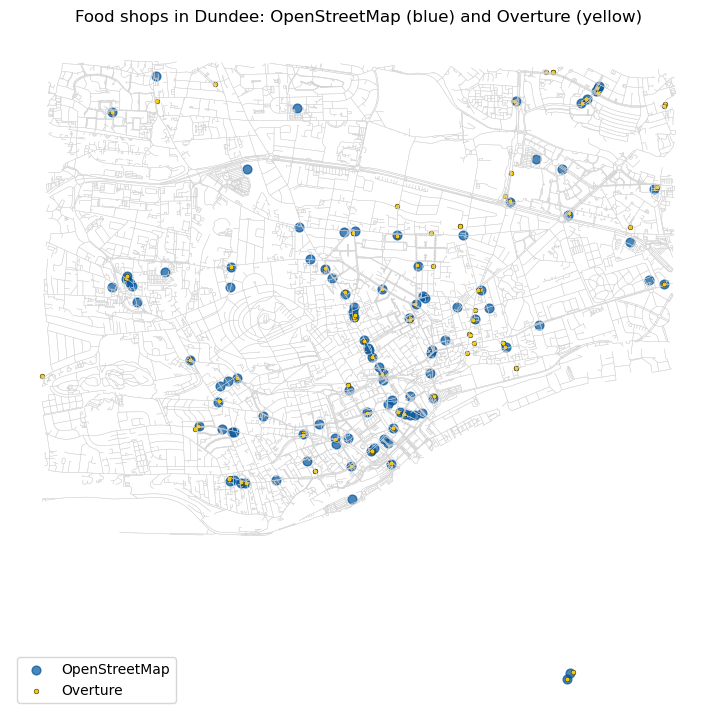

In [52]:
# Next i am mapping food shops from OSM and Overture with the new confidence threshold of 0.8
# Using the location map example from Lab 5, Part 4

fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
shops.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_shops.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Food shops in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()


Figure 5. Comparison of OpenStreetMap (blue) and Overture Maps (yellow) food-shop locations across Dundee, using an Overture confidence threshold of 0.8.
![food_shops_dundee](screenshots/food_dundee.png)

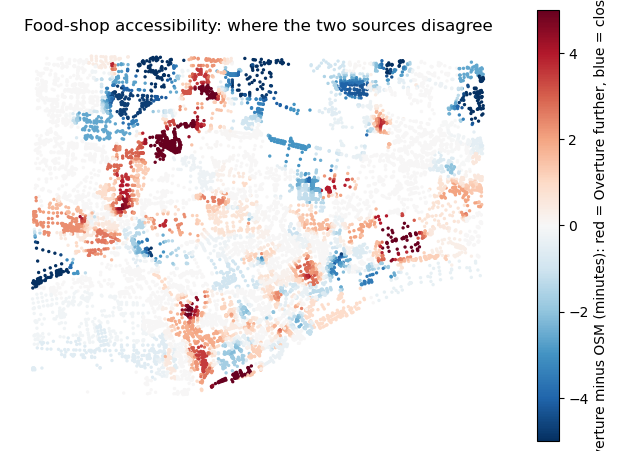

In [53]:
#then i am also mapping where Overture and OSM give different walking times to the nearest food shop
# the negative values mean Overture is closer; positive values mean OSM is closer

nodes["difference"] = nodes["nearest_min_overture"] - nodes["nearest_min"]

ax = nodes.plot(column="difference", cmap="RdBu_r", vmin=-5, vmax=5, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Overture minus OSM (minutes): red = Overture further, blue = closer", "shrink": 0.7})
ax.set_title("Food-shop accessibility: where the two sources disagree")
ax.set_axis_off()
plt.show()

Figure 6. Difference in walking time to the nearest food shop using Overture Maps and OpenStreetMap in Dundee. Blue indicates shorter journeys using Overture, while red indicates shorter journeys using OSM.

![food_shop_acessibility_difference](screenshots/food_access_dundee.png)

In [54]:
#Next is to recalculate the accessibility confidence to 0.8 modifying the code from lab 5 again
# and comparing the results with the same OSM food-shop locations as before

overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

,OpenStreetMap,Overture
Median minutes to nearest food shop,3.9,4.7
% of junctions within 10 minutes,87.5,81.9


In [55]:
#that cell output is identical to the food-shops results which is a problem
#I am suspecting that the shops variable still contains food shopswhile Overture_shops contains pharmacies - meaning my current comparison might still be mixng two different services
# So changing the service category from food shops to pharmacies here:

shops = dundee_services[dundee_services["service"] == "Pharmacy"].copy()

is_pharmacy = places["basic_category"].str.contains("pharmacy", na=False)
overture_shops = places[is_pharmacy & (places["confidence"] >= 0.5)].copy()

print("Pharmacies in OpenStreetMap:", len(shops))
print("Pharmacies in Overture:", len(overture_shops))


Pharmacies in OpenStreetMap: 19
Pharmacies in Overture: 35


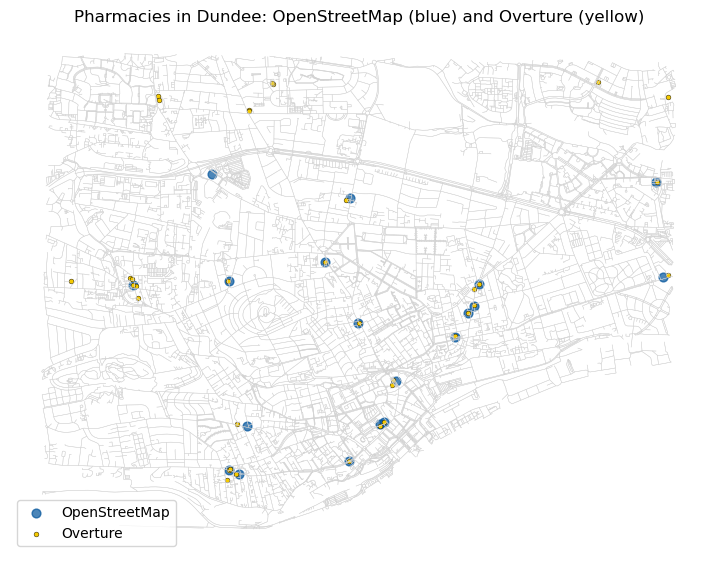

In [56]:
#next is comparing the mapped pharmacy locations with Openstreetmap and Overture

fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
shops.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_shops.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Pharmacies in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

Figure 7. Comparison of pharmacy locations recorded in OpenStreetMap (blue) and Overture Maps (yellow) across Dundee, using an Overture confidence threshold of 0.5.
![pharmacy_locations_dundee](screenshots/pharmacy_dundee.png)

In [57]:
#next we first need to calculate the nearest OSM pharmacy using the same method as before
#this is needed because nodes["nearest_min"] still contains food-shop walking times
#adapting code from lab 5 - i combined multike cells here togather for this:

shops["node"] = ox.distance.nearest_nodes(G, shops.geometry.x, shops.geometry.y)
nearest = nx.multi_source_dijkstra_path_length(G, set(shops["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

# this is calculating nearest-pharmacy walking times using Overture
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

# next is to compare the pharmacy access using the same two measures as Challenge 3.1
comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest pharmacy", "% of junctions within 10 minutes"])
comparison.round(1)

,OpenStreetMap,Overture
Median minutes to nearest pharmacy,8.3,7.3
% of junctions within 10 minutes,58.4,69.7


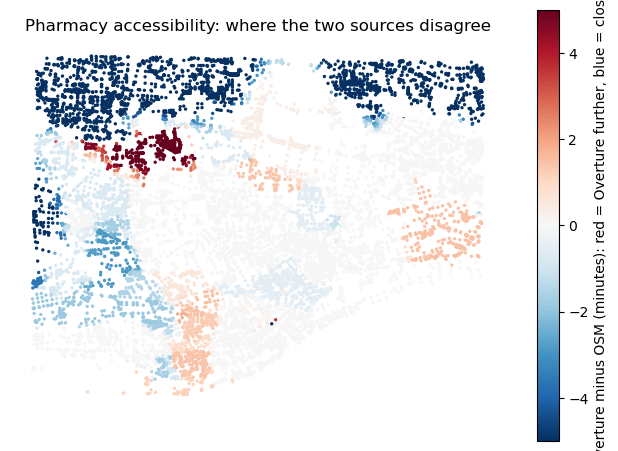

In [58]:
#this cell is optional but i thought i could be good to include since it is used in lab 5 part 4 example
#this is mapping where OSM and Overture give different walking times to pharmacies
nodes["difference"] = nodes["nearest_min_overture"] - nodes["nearest_min"]

ax = nodes.plot(column="difference", cmap="RdBu_r", vmin=-5, vmax=5, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Overture minus OSM (minutes): red = Overture further, blue = closer", "shrink": 0.7})
ax.set_title("Pharmacy accessibility: where the two sources disagree")
ax.set_axis_off()
plt.show()

Figure 8. Difference in walking time to the nearest pharmacy using Overture Maps and OpenStreetMap in Dundee. Blue indicates shorter journeys using Overture, while red indicates shorter journeys using OSM.

![pharmacy walking_difference](screenshots/pharmacy_difference.png)

### Description
**Challenge 3.1-description and insights:**
For this part of the challenge, i followed the Overture and Openstreetmaps comparison from lab 5 part 4 and increasing the Overture confidence threshold from 0.5 to 0.8 while also keeping the same food-shop catgeories and the dundee walking network. Then i also recalulculated the OSM food-shop accessibility because challenge 2 had changed it to schools.
Increasing the threshold reduced the number of Overture food shops from 125 to 95, compared with 104 in OSM. Then the median walking time using Overture increased from 4.1 to 4.7 minutes, while the percentage of junctions within 10 minutes decreased from 87.5% to 81.9%. This is a good example of showing how removing lower-confidence records can reduce the measured accessibility - even though the underlying walking network was unchanged. However, the higher threshold doesn't necessarily mean that all the retained shops are correct, or that the excluded shops are incorrect as a quick note.

**Challenge 3.2 - descriptions and insights**:
For this part of the challenge, I changed the service category to pharmacies ( using the same OSM and Overture filtering and accessibility methods from Lab 5 again). I then selected pharmacy locations from both datasets using an Overture confidence threshold of 0.5, and then I recalculated their nearest-service walking times as required.
OSM contained 19 pharmacies compared with 35 in Overture and the median walking time was 8.3 minutes using OSM and 7.3 minutes using Overture, while the percentage of junctions within 10 minutes was 58.4% and 69.7% respectively. Figure 7 shows several overlapping pharmacy locations, alongside records found in only one source. Figure 8 shows shorter Overture journeys across much of the northern network -  although some western and central areas appear to favour OSM. This demonstrates how differences in mapped service locations can affect accessibility estimates - although to note that neither dataset is necessarily complete or fully up to date.

## Challenge 4: 10-Minute Neighbourhood Accessibility in Perth
For this challenge, I am using the Perth accessibility  example from lab 5 part 5 but I am changing the walking threshold from 1200m (15 mins) to 800m (10 mins), to investigate how many residential junctionscan reach all 5 essential service catgeories within the shorter walking distance.

In [65]:
#Challenge 4 - using the Perth study area and services from lab 5 part 5
#but changing the WALK_LIMIT from 1200m to 800m to look at 10-min accessibility:
PERTH = (56.3960, -3.4370)       
AREA = 1500                        # metres: the neighbourhood area 
WALK_LIMIT = 800                  # 10 minutes walking (changed from 1200m)
BIKE_LIMIT = 5000                  # 20 minutes cycling

SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [66]:
#loading the supplied Perth walking and cycling networks
#then projecting to British National Grid (BNG) so network distances are measured in metres
G_walk = ox.load_graphml("data/perth_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:27700").to_undirected()

G_bike = ox.load_graphml("data/perth_bike.graphml")
G_bike = ox.project_graph(G_bike, to_crs="EPSG:27700").to_undirected()

print("Walk network:", len(G_walk), "junctions | Bike network:", len(G_bike), "junctions")

Walk network: 6595 junctions | Bike network: 9236 junctions


In [67]:
# Next i am identifying residential junctions within the 1.5 km neighbourhood
# and using residential land use areas as a proxy for where people live
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

residential = gpd.read_file("data/perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([PERTH[1]], [PERTH[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(AREA).iloc[0]

homes = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()
print(len(homes), "residential junctions in the neighbourhood")

1067 residential junctions in the neighbourhood


In [68]:
# Next up is loading the five essential service types from the supplied Perth dataset
# then calculating shortest walking and cycling distances to the nearest service in each category
# I am using the network accessibility method demonstrated in Lab 5 again

services = gpd.read_file("data/perth_services.gpkg").to_crs("EPSG:27700")
homes_on_bike = ox.distance.nearest_nodes(G_bike, homes.geometry.x, homes.geometry.y)   # the same homes on the bike network

for name in SERVICES:
    points = services[services["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walk, points.x, points.y)
    bike_targets = ox.distance.nearest_nodes(G_bike, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walk, set(walk_targets), weight="length")
    bike_dist = nx.multi_source_dijkstra_path_length(G_bike, set(bike_targets), weight="length")

    homes[name + " walk (m)"] = [walk_dist.get(n) for n in homes.index]
    homes[name + " bike (m)"] = [bike_dist.get(n) for n in homes_on_bike]
    print(f"{name:<17} {len(points):>5} found")

School               31 found
Food shop            48 found
Healthcare           29 found
Park                 28 found
Public transport    464 found


In [70]:
#next is calculating the percentage of residential junctions within 800 m of each service
# and keeping the original 20-minute cycling comparison unchanged

results = pd.DataFrame(index=list(SERVICES))
results["% homes within 10-min walk"] = [(homes[s + " walk (m)"] <= WALK_LIMIT).mean() * 100 for s in SERVICES]
results["% homes within 20-min cycle"] = [(homes[s + " bike (m)"] <= BIKE_LIMIT).mean() * 100 for s in SERVICES]
results.round(0)

,% homes within 10-min walk,% homes within 20-min cycle
School,65.0,100.0
Food shop,77.0,100.0
Healthcare,68.0,100.0
Park,65.0,100.0
Public transport,100.0,100.0


In [ ]:
#next up is counting how many of the five service categories are within an 800 m walk of each residential junction
# and then mapping the results to identify where the shorter 10-minute threshold is met

homes["services_walk"] = sum((homes[s + " walk (m)"] <= WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(8, 8), legend_kwds={"label": "Essential services within a 10-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: essential services within a 10-minute walk")
ax.set_axis_off()
plt.show()

print(f"{(homes['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")


Figure 9: Showing the number of essential service categories accessible within a 10-minute (800 m) walk from residential street junctions in the selected Perth neighbourhood - dark green indicates access to more of the five service categories, then yellow, orange and red indicate fewer accessible services. The grey boundary represents the 1.5 km neighbourhood study area.
![perth_10_min_distance](screenshots/perth_walking.png)

In [73]:
#quickly looking at how many homes still reach all 5 services: we have the percentage but not the number so just adding that here
print((homes["services_walk"] == 5).sum(), "residential junctions can reach all 5 services within 10 minutes")

323 residential junctions can reach all 5 services within 10 minutes


### Description
**challenge 4 - description and insights**:
For this challenge, I followed the Perth 15-minute neighbourhood example from Lab 5 part 5, and changing the walking threshold from 1,200 m to 800 m to investigate Scotland's shorter 10-minute local living concept as required. I kept the same study area, five service categories and walking/cycling network calculations and only changed the walking threshold and the figure labels from the lab code as well.
The results showed that 323 of the 1,067 residential junctions (30.3%) could reach all five service categories within a 10-minute walk. Then i found that public transport was the most accessible service (100%), while schools and parks were the least accessible (65% each). Figure 9 is showing higher accessibility in parts of the eastern and southwestern neighbourhood - with some outer areas having access to fewer services. 
This all demonstrates how the shorter walking threshold can reveal gaps in access to everyday services, even where individual services are relatively accessible. 
However, residential junctions are only a proxy for homes, and the analysis does not account for service quality or capacity as a note.

## Challenge 5: School Accessibility and 15-Minute Walking Gaps in Perth
Change the services in 5.4 from "Healthcare" to "Food shop" or "School". Where are the biggest gaps?

For this challenge, I have adapted the service-accessibilites example from lab 5 part 4 and i am then changing the service type from healthcare to schools as requested. Then using the same perth walking network to investigate which streets are within a 15 mins walk of a school and idenifying where the main gaps occur.

In [79]:
# first i need to return to the original 15-minute walking threshold from Lab 5 and the healthcare example
# because challenge 4 used 800 m for a 10-minute walk i need to change this back to 1200 m

WALK_LIMIT = 1200  # 15 minutes walking at 80 metres per minute

In [ ]:
# main part of challenge 5 - changing the service type from Healthcare to School
# I am again using the same network shortest-path method from Lab 5, Part 6.4
# Then i need to be mapping which streets are within a 15-minute walk of at least one school

school = services[services["service"] == "School"]
school_nodes = set(ox.distance.nearest_nodes(G_walk, school.geometry.x, school.geometry.y))
dist_to_school = nx.multi_source_dijkstra_path_length(G_walk, school_nodes, cutoff=WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_school)) & walk_edges["v"].isin(set(dist_to_school))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#C22A22", linewidth=0.8)
school.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of a school (red); gaps in grey")
ax.set_axis_off()
plt.show()

#reproducability note: walk_edges.reset_index() line expects walk_edges to be created by the challenge 4 code, so need to make sure to run challenge 4 before this

Figure 10: Modelled street-network accessibility to schools within a 15-minute (1,200 m) walk in Perth. Red street segments indicate streets classified as accessible while the grey segments show gaps in coverage, then the black points represent mapped school locations, and the black circle outlines the 1.5 km neighbourhood study area.

![perth_school_15_min](screenshots/perth_school_walk.png)

### Description
**challenge 5 - description and insights**:
For this challenge, I adapted the service-accessibility example from Lab 5 part 6.4 and then changed the service type from healthcare to schools while keeping the same Perth walking network. I also restored the original walking threshold of 1,200 m, as Challenge 4 had reduced this to 800 m.
Figure 10 shows that a large proportion of the street network is within a 15-minute walk of a school (especiialy across the western, central and northern sections). The largest gaps appear towards the eastern and northeastern parts of the neighbourhood - there are some smaller gaps around the central and southeastern areas. 
This challenge and its outputs demonstrates how school locations and network connectivity can influence walking accessibility, even within a relatively small neighbourhood. 
However, the results only represent proximity to mapped schools and don't account for school catchments, capacity or whether individual residents can attend them as a note.

## Challenge 6: Park Accessibility in Stirling
Try any small city in the world. Replace the loading lines in 6.1 with these downloads, then run Part 6 again. Downloads can take a few minutes and may fail if the OpenStreetMap servers are busy; if so, try again later.

In [ ]:

CITY = "Anstruther, Fife"
CENTRE = (56.22486, -2.69652)
DIST = 1500
CATCHMENT = 1200                     # metres: a 15-minute walk

# Downloading the walking network
G_city = ox.graph_from_point(CENTRE, dist=DIST, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]

# Downloading mapped park polygons and calculating their area
parks = ox.features_from_point(CENTRE, tags={"leisure": "park"}, dist=DIST).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area

# Downloading buildings as a proxy for demand
buildings = ox.features_from_point(CENTRE, tags={"building": True}, dist=DIST).to_crs(crs)

print(len(parks), "parks and", len(buildings), "buildings in", CITY)


In [ ]:
#next up is to assign parks and buildings to their nearest walking-network junctions
#and using buildings at each junction as a measure of demand

parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings
demand.head()

In [ ]:
#next up is to be calculating park area per building within each park's 15-minute catchment
# again i am following the 2SFCA method demonstrated in Lab 5, Part 7

reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

In [ ]:
# the next step is to be adding the park-space ratios for each junction
# as this considers both park area and the number of buildings sharing park access

city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
homes_city["park_access"].describe().round(0)

In [ ]:
#then need to map the 2SFCA park accessibility scores for Stirling- with the darker green points indicate higher estimated park space per building

fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

In [ ]:
#for reproducability, if stirling download dails or if it is too big,use:
CENTRE = (56.1165, -3.9369)
DIST = 2000

G_city = ox.graph_from_point(CENTRE, dist=DIST, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]

parks = ox.features_from_point(CENTRE, tags={"leisure": "park"}, dist=DIST).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area

buildings = ox.features_from_point(CENTRE, tags={"building": True}, dist=DIST).to_crs(crs)

### Description
...